# Detecção de objetos com YOLO: controle e copo

**Atividade 1 – Fase 6 (FarmTech Solutions)**

Este notebook treina, valida e testa dois modelos YOLO para detectar duas classes de objetos bem diferentes entre si: `controle` (objeto A) e `copo` (objeto B). A diferença entre os dois experimentos é o número de épocas (30 e 60), para comparar acurácia, erro e desempenho.


## 1. Acesso ao dataset

Monta o Google Drive para acessar o dataset (imagens e rotulações feitas no Make Sense) e salvar os resultados dos treinamentos.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


Define o caminho da pasta do dataset, que contém as subpastas `images` e `labels`, cada uma dividida em `train`, `val` e `test`.

In [ ]:
caminho_dataset = "/content/drive/MyDrive/Fase 6/Dataset"

print(caminho_dataset)

/content/drive/MyDrive/Fase 6/Dataset


## 2. Verificação do dataset

Conta as imagens e labels de cada divisão. Cada imagem deve ter um arquivo de label correspondente.

Foram usadas 40 imagens do objeto A (controle) e 40 do objeto B (copo), divididas em 32 para treino, 4 para validação e 4 para teste por objeto:

| Divisão | Imagens | Labels |
|---|---|---|
| train | 64 | 64 |
| val | 8 | 8 |
| test | 8 | 8 |

In [ ]:
import os

for pasta in ["train", "val", "test"]:

    imagens = os.listdir(
        os.path.join(caminho_dataset, "images", pasta)
    )

    labels = os.listdir(
        os.path.join(caminho_dataset, "labels", pasta)
    )

    print(f"{pasta}:")
    print(f"  Imagens: {len(imagens)}")
    print(f"  Labels:  {len(labels)}")
    print()

train:
  Imagens: 64
  Labels:  64

val:
  Imagens: 8
  Labels:  8

test:
  Imagens: 8
  Labels:  8



## 3. Instalação da biblioteca

Instala o **Ultralytics**, biblioteca que fornece o modelo YOLO11 e as funções de treinamento, validação e predição.

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 6.8 MB/s eta 0:00:00


## 4. Configuração do `data.yaml`

Cria o arquivo de configuração que o YOLO usa para localizar os dados. Ele informa o caminho base, as pastas de treino, validação e teste e os nomes das classes:

- `0`: controle
- `1`: copo

In [ ]:
data_yaml = """
path: /content/drive/MyDrive/Fase 6/Dataset

train: images/train
val: images/val
test: images/test

names:
  0: controle
  1: copo
"""

with open("/content/drive/MyDrive/Fase 6/data.yaml", "w") as arquivo:
    arquivo.write(data_yaml)

print(data_yaml)


path: /content/drive/MyDrive/Fase 6/Dataset

train: images/train
val: images/val
test: images/test

names:
  0: controle
  1: copo



### Conferência do formato das anotações

Lê uma label de exemplo para confirmar o formato YOLO, em que cada linha é:

`classe x_centro y_centro largura altura`

As coordenadas são normalizadas (valores entre 0 e 1).

In [ ]:
import os

labels_train = os.listdir(
    os.path.join(caminho_dataset, "labels", "train")
)

print("Quantidade de labels:", len(labels_train))

print("\nPrimeira label:", labels_train[0])

with open(
    os.path.join(caminho_dataset, "labels", "train", labels_train[0]),
    "r"
) as arquivo:

    print("Conteúdo:", arquivo.read())

Quantidade de labels: 64

Primeira label: controle23.txt
Conteúdo: 0 0.502724 0.495994 0.985577 0.988782


Confere a estrutura final das pastas. Os arquivos `.cache` em `labels` são gerados automaticamente pelo YOLO para acelerar leituras futuras.

In [ ]:
import os

print("Conteúdo de images:")
print(os.listdir(os.path.join(caminho_dataset, "images")))

print("\nConteúdo de labels:")
print(os.listdir(os.path.join(caminho_dataset, "labels")))

Conteúdo de images:
['train', 'test', 'val']

Conteúdo de labels:
['test', 'train', 'val', 'train.cache', 'val.cache', 'test.cache']


## 5. Treinamento, validação e teste

### Etapa 1 – Treinamento (Modelo 1: 30 épocas)

Treina o **YOLO11n** (versão leve e pré-treinada) por 30 épocas, com imagens de 640x640 e batch de 16. A cada época o modelo é avaliado no conjunto de **validação**, e os melhores pesos (`best.pt`) são salvos no Drive, na pasta `results`.

O treinamento foi feito em CPU e levou cerca de 0,41 hora.

**Resultado na validação (melhor modelo):**

| Classe | Precision | Recall | mAP@50 | mAP@50-95 |
|---|---|---|---|---|
| Geral | 0,892 | 1,000 | 0,995 | 0,548 |
| controle | 0,817 | 1,000 | 0,995 | 0,532 |
| copo | 0,966 | 1,000 | 0,995 | 0,563 |

In [ ]:
from ultralytics import YOLO


model = YOLO("yolo11n.pt")

results_30 = model.train(
    data="/content/drive/MyDrive/Fase 6/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    project="/content/drive/MyDrive/Fase 6/results",
    name="yolo_30_epochs"
)

Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Fase 6/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_30_epochs-8, nbs=64, nms=None, opset=None, o

### Etapa 3 – Teste do Modelo 1

Carrega os melhores pesos (`best.pt`) do treino de 30 épocas mais recente e avalia no conjunto de **teste**, que não foi usado no treinamento nem na escolha do melhor modelo.

| Classe | Precision | Recall | mAP@50 | mAP@50-95 |
|---|---|---|---|---|
| Geral | 0,818 | 0,875 | 0,870 | 0,563 |
| controle | 0,652 | 0,750 | 0,745 | 0,588 |
| copo | 0,985 | 1,000 | 0,995 | 0,539 |

In [ ]:
!pip install -q ultralytics

import glob
import os
from ultralytics import YOLO

pesos_30 = sorted(
    glob.glob("/content/drive/MyDrive/Fase 6/results/yolo_30_epochs*/weights/best.pt"),
    key=os.path.getmtime
)
assert pesos_30, "Nenhum best.pt de 30 épocas encontrado em Fase 6/results"
print("Pesos usados:", pesos_30[-1])

model = YOLO(pesos_30[-1])

metrics_30 = model.val(
    data="/content/drive/MyDrive/Fase 6/data.yaml",
    split="test"
)

print(metrics_30)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 6.6 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Pesos usados: /content/drive/MyDrive/Fase 6/results/yolo_30_epochs-8/weights/best.pt
Ultralytics 8.4.176 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.7±0.2 ms, read: 0.1±0.0 MB/s, size: 9.0 KB)
val: Scanning /content/drive/MyDrive/Fase 6/Dataset/labels/test

### Predições nas imagens de teste (Modelo 1)

Roda o modelo nas imagens de teste com confiança mínima de 0,25. Das 8 imagens, o modelo detectou o objeto correto em 7. Em `copo19.jpg` não houve nenhuma detecção, e `controle9.jpg` teve uma detecção a mais que o esperado (2 controles). As imagens processadas são salvas e exibidas na seção 6.

In [ ]:
results_test = model.predict(
    source="/content/drive/MyDrive/Fase 6/Dataset/images/test",
    conf=0.25,
    save=True
)


image 1/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/controle19.jpg: 640x640 2 controles, 192.5ms
image 2/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/controle29.jpg: 640x640 1 controle, 186.9ms
image 3/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/controle39.jpg: 640x608 1 controle, 177.6ms
image 4/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/controle9.jpg: 640x640 1 controle, 170.8ms
image 5/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/copo19.jpg: 640x640 3 copos, 170.9ms
image 6/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/copo29.jpg: 640x640 1 copo, 172.1ms
image 7/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/copo39.jpg: 640x640 1 controle, 1 copo, 174.8ms
image 8/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/copo9.jpg: 640x640 3 copos, 191.9ms
Speed: 5.8ms preprocess, 179.7ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


### Modelo 2: 60 épocas

Repete o treinamento (etapas de treino e validação) com os mesmos parâmetros, mudando apenas o número de épocas para 60. O objetivo é verificar se treinar por mais tempo melhora o desempenho. O treinamento levou cerca de 0,81 hora.

**Resultado na validação (melhor modelo):**

| Classe | Precision | Recall | mAP@50 | mAP@50-95 |
|---|---|---|---|---|
| Geral | 0,970 | 1,000 | 0,995 | 0,782 |
| controle | 0,968 | 1,000 | 0,995 | 0,839 |
| copo | 0,972 | 1,000 | 0,995 | 0,726 |

In [ ]:
model_60 = YOLO("yolo11n.pt")

results_60 = model_60.train(
    data="/content/drive/MyDrive/Fase 6/data.yaml",
    epochs=60,
    imgsz=640,
    batch=16,
    project="/content/drive/MyDrive/Fase 6/results",
    name="yolo_60_epochs"
)

Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Fase 6/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_60_epochs-2, nbs=64, nms=None, opset=None, o

### Teste do Modelo 2

Avalia o modelo de 60 épocas no mesmo conjunto de **teste**.

| Classe | Precision | Recall | mAP@50 | mAP@50-95 |
|---|---|---|---|---|
| Geral | 0,986 | 0,983 | 0,995 | 0,469 |
| controle | 1,000 | 0,965 | 0,995 | 0,621 |
| copo | 0,971 | 1,000 | 0,995 | 0,317 |

In [ ]:
import glob
import os
from ultralytics import YOLO

pesos_60 = sorted(
    glob.glob("/content/drive/MyDrive/Fase 6/results/yolo_60_epochs*/weights/best.pt"),
    key=os.path.getmtime
)

assert pesos_60, "Nenhum best.pt de 60 épocas encontrado em Fase 6/results"
print("Pesos carregados:", pesos_60[-1])

model_60 = YOLO(pesos_60[-1])

metrics_60 = model_60.val(
    data="/content/drive/MyDrive/Fase 6/data.yaml",
    split="test"
)

print(metrics_60)

Pesos carregados: /content/drive/MyDrive/Fase 6/results/yolo_60_epochs-2/weights/best.pt
Ultralytics 8.4.176 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 8.0±3.0 MB/s, size: 8.0 KB)
val: Scanning /content/drive/MyDrive/Fase 6/Dataset/labels/test.cache... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 1.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.7s/it 1.7s
                   all          8          8      0.986      0.983      0.995      0.469
              controle          4          4          1      0.965      0.995      0.621
                  copo          4          4      0.971          1      0.995      0.317
Speed: 7.5ms preprocess, 199.2ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/detect/val-2


## 6. Imagens de teste processadas pelos modelos

A primeira célula localiza as pastas dos treinamentos no Drive (o YOLO acrescenta um sufixo numérico ao nome a cada novo treino) e carrega os melhores pesos dos dois modelos. Ela é independente das anteriores, então pode ser executada sozinha, mesmo depois de reiniciar o ambiente do Colab.

As células seguintes geram as predições dos dois modelos sobre as 8 imagens de teste, salvam os resultados no Drive (pasta `predicoes`, para não se perderem quando o Colab fechar) e exibem cada imagem com as caixas e as confianças detectadas.

In [ ]:
import os
import glob
import pandas as pd
from google.colab import drive
from ultralytics import YOLO

if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

BASE_RESULTS = "/content/drive/MyDrive/Fase 6/results"


def achar_treino(prefixo, epocas):
    """Devolve a pasta do treino mais recente que tenha best.pt.
    Se a pasta tiver results.csv, dá preferência à que tem o número de épocas esperado."""
    pastas = [
        p for p in glob.glob(f"{BASE_RESULTS}/{prefixo}*")
        if os.path.exists(os.path.join(p, "weights", "best.pt"))
    ]
    if not pastas:
        existentes = os.listdir(BASE_RESULTS) if os.path.isdir(BASE_RESULTS) else "pasta results não encontrada"
        raise FileNotFoundError(
            f"Nenhum treino '{prefixo}*' com weights/best.pt em {BASE_RESULTS}. Conteúdo: {existentes}"
        )

    def n_epocas(pasta):
        csv = os.path.join(pasta, "results.csv")
        return len(pd.read_csv(csv)) if os.path.exists(csv) else None

    certas = [p for p in pastas if n_epocas(p) == epocas]
    escolhidas = certas or pastas
    return max(escolhidas, key=lambda p: os.path.getmtime(os.path.join(p, "weights", "best.pt")))


pasta_30 = achar_treino("yolo_30_epochs", 30)
pasta_60 = achar_treino("yolo_60_epochs", 60)
print("Modelo de 30 épocas:", pasta_30)
print("Modelo de 60 épocas:", pasta_60)

modelo_30 = YOLO(os.path.join(pasta_30, "weights", "best.pt"))
modelo_60 = YOLO(os.path.join(pasta_60, "weights", "best.pt"))

Modelo de 30 épocas: /content/drive/MyDrive/Fase 6/results/yolo_30_epochs-8
Modelo de 60 épocas: /content/drive/MyDrive/Fase 6/results/yolo_60_epochs-2


In [ ]:
for nome, m in [("30_epocas", modelo_30), ("60_epocas", modelo_60)]:
    m.predict(
        source="/content/drive/MyDrive/Fase 6/Dataset/images/test",
        conf=0.25,
        save=True,
        project="/content/drive/MyDrive/Fase 6/predicoes",
        name=nome,
        exist_ok=True
    )


image 1/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/controle19.jpg: 640x640 2 controles, 290.0ms
image 2/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/controle29.jpg: 640x640 1 controle, 188.0ms
image 3/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/controle39.jpg: 640x608 1 controle, 163.5ms
image 4/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/controle9.jpg: 640x640 1 controle, 186.1ms
image 5/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/copo19.jpg: 640x640 3 copos, 176.4ms
image 6/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/copo29.jpg: 640x640 1 copo, 179.5ms
image 7/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/copo39.jpg: 640x640 1 controle, 1 copo, 179.8ms
image 8/8 /content/drive/MyDrive/Fase 6/Dataset/images/test/copo9.jpg: 640x640 3 copos, 177.1ms
Speed: 6.7ms preprocess, 192.5ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/Fase 6/predicoes/30_epocas

image 1/8 /content/d


===== Predições do modelo de 30 epocas =====
controle19.jpg


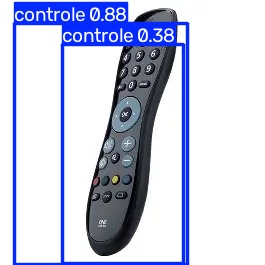

controle29.jpg


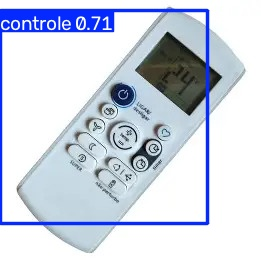

controle39.jpg


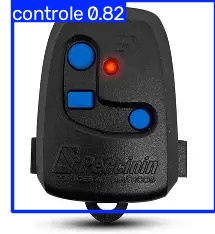

controle9.jpg


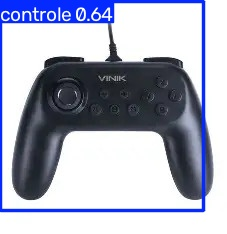

copo19.jpg


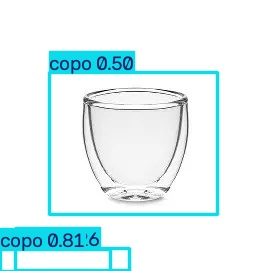

copo29.jpg


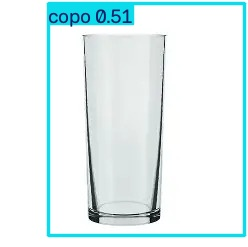

copo39.jpg


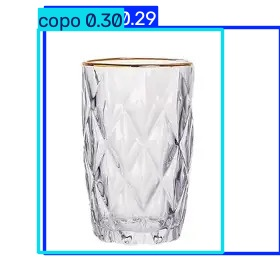

copo9.jpg


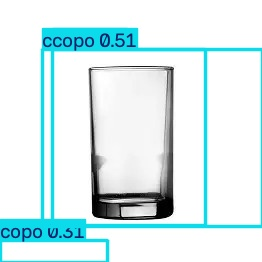


===== Predições do modelo de 60 epocas =====
controle19.jpg


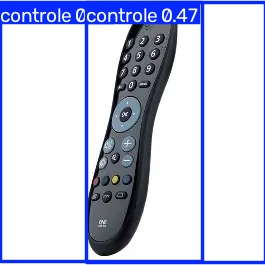

controle29.jpg


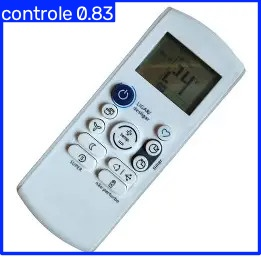

controle39.jpg


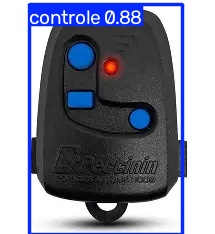

controle9.jpg


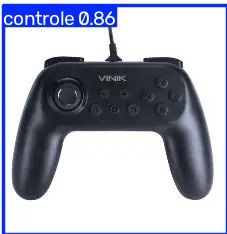

copo19.jpg


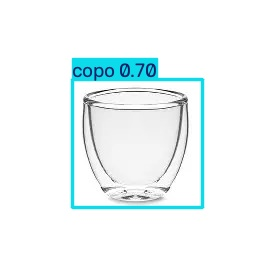

copo29.jpg


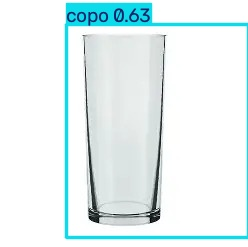

copo39.jpg


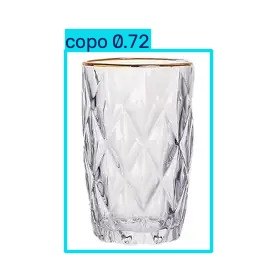

copo9.jpg


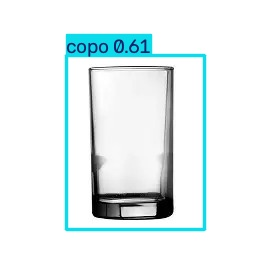

In [ ]:
import glob
from IPython.display import display, Image

for nome in ["30_epocas", "60_epocas"]:
    print(f"\n===== Predições do modelo de {nome.replace('_', ' ')} =====")
    imagens = sorted(glob.glob(f"/content/drive/MyDrive/Fase 6/predicoes/{nome}/*.jpg"))
    if not imagens:
        print("Nenhuma imagem encontrada. Execute antes a célula de predições.")
    for caminho in imagens:
        print(caminho.split("/")[-1])
        display(Image(filename=caminho, width=400))

## 7. Comparação do erro e do tempo de treino

A célula abaixo lê o arquivo `results.csv` de cada treinamento e mostra as losses da última época (erro de caixa e de classificação, no treino e na validação) junto com o tempo de treino.

In [ ]:
import os
import pandas as pd

log_treino = {
    "30 épocas": {"box": 0.839, "cls": 0.715, "horas": 0.409},
    "60 épocas": {"box": 0.792, "cls": 0.618, "horas": 0.814},
}

linhas = []
for nome, pasta in [("30 épocas", pasta_30), ("60 épocas", pasta_60)]:
    csv = os.path.join(pasta, "results.csv")
    log = log_treino[nome]
    if os.path.exists(csv):
        df = pd.read_csv(csv)
        df.columns = df.columns.str.strip()
        ultima = df.iloc[-1]
        linhas.append({
            "Modelo": nome,
            "train box_loss": round(ultima["train/box_loss"], 3),
            "train cls_loss": round(ultima["train/cls_loss"], 3),
            "val box_loss": round(ultima["val/box_loss"], 3),
            "val cls_loss": round(ultima["val/cls_loss"], 3),
            "Tempo de treino (h)": log["horas"],
        })
    else:
        print(f"results.csv não encontrado em {pasta}: usando as losses de treino do log de treinamento.")
        linhas.append({
            "Modelo": nome,
            "train box_loss": log["box"],
            "train cls_loss": log["cls"],
            "val box_loss": None,
            "val cls_loss": None,
            "Tempo de treino (h)": log["horas"],
        })

pd.DataFrame(linhas)

,Modelo,train box_loss,train cls_loss,val box_loss,val cls_loss,Tempo de treino (h)
0,30 épocas,0.839,0.715,1.499,1.379,0.409
1,60 épocas,0.792,0.618,1.178,0.597,0.814


## 8. Avaliação e comparação dos modelos

Foram treinados dois modelos YOLO11n para detectar as classes `controle` e `copo`: um com 30 épocas e outro com 60. Ambos foram avaliados na validação (usada durante o treino) e no teste (separado previamente, nunca visto pelo modelo).

### Desempenho no conjunto de teste

| Métrica | 30 épocas | 60 épocas |
|---|---|---|
| Precision | 0,818 | **0,986** |
| Recall | 0,875 | **0,983** |
| mAP@50 | 0,870 | **0,995** |
| mAP@50-95 | **0,563** | 0,469 |

### Desempenho no conjunto de validação

| Métrica | 30 épocas | 60 épocas |
|---|---|---|
| Precision | 0,892 | **0,970** |
| Recall | 1,000 | 1,000 |
| mAP@50 | 0,995 | 0,995 |
| mAP@50-95 | 0,548 | **0,782** |

### Erro (loss) e tempo de treino

Losses de treino na última época, conforme o log de treinamento:

| Loss | 30 épocas | 60 épocas |
|---|---|---|
| box_loss | 0,839 | **0,792** |
| cls_loss | 0,715 | **0,618** |
| dfl_loss | 1,565 | 1,568 |
| Tempo de treino | **0,41 h** | 0,81 h |

### Análise

- **Erro:** o treino de 60 épocas terminou com box_loss e cls_loss menores, ou seja, o modelo se ajustou melhor aos dados de treino. A dfl_loss ficou praticamente igual. O custo foi o dobro do tempo de treinamento.
- **Detecção das classes (teste):** o modelo de 60 épocas foi melhor em Precision, Recall e mAP@50. Praticamente não deixou de detectar nem errou objetos no teste. O modelo de 30 épocas falhou em `copo19.jpg` (sem detecção) e gerou uma detecção extra em `controle9.jpg`.
- **Qualidade das caixas:** no teste, o mAP@50-95, que exige caixas mais precisas, foi maior no modelo de 30 épocas (0,563 contra 0,469), principalmente na classe `copo`. Na validação aconteceu o contrário (0,548 contra 0,782). Essa inversão mostra que o mAP@50-95 é instável neste experimento.
- **Instabilidade:** validação e teste têm só 8 imagens (4 por classe). Basta uma caixa um pouco deslocada para mudar muito as métricas, e durante o treino os valores de validação oscilaram bastante entre épocas. Diferenças pequenas devem ser vistas com cautela. Além disso, as caixas rotuladas ocupam boa parte da imagem (a label conferida na seção 2 cobre cerca de 98% da largura e da altura), o que também pesa nas métricas mais exigentes.

### Conclusão

O modelo de **60 épocas** teve o melhor desempenho geral: menor erro de treino, melhor Precision e Recall no teste e melhor mAP@50-95 na validação. O ganho veio com o dobro do tempo de treino. Para detectar corretamente se o objeto é um controle ou um copo, que é o objetivo para a FarmTech Solutions, os dois modelos funcionam, e o de 60 épocas é mais confiável. Como o dataset é pequeno, os resultados são indicativos. Um dataset maior, com mais variação de fundo, ângulo e iluminação, daria uma comparação mais segura, e seria possível melhorar a precisão das caixas com rotulações mais justas ao objeto.